In [1]:
#!/usr/bin/env python
# coding: utf-8

# parameters
DEVICE      = 'cpu'
SEED        = 42      # change to 123 or 777 for other runs
FRICTION_ON = False    # True → DMF (with friction)  |  False → plain DM

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.distributions as TD
import matplotlib
#matplotlib.use('Agg')
%matplotlib inline
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import gaussian_kde
from tqdm import tqdm
from IPython.display import clear_output
import random, os, sys
sns.set_theme(style="ticks", palette="pastel")

from OFM.ofmsrc.dgm_utils import visualize_2d_samples_groups, visualize_2d_map
from OFM.ofmsrc.tools import EMA
from OFM.ofmsrc.distributions import Sampler, StandardNormalSampler

## Gaussian Mixture Sampler

In [2]:

def seed_everything(seed=42):
    np.random.seed(seed)
    torch.random.manual_seed(seed)
    random.seed(seed)


# ── Gaussian Mixture Sampler ──────────────────────────────────────────────────

class GaussianMixture(Sampler):
    """
    parameters: list of dicts with keys:
        "mean" : list of length dim
        "std"  : list of length dim  (diagonal covariance)
    All components equally weighted.
    """
    def __init__(self, parameters, device='cpu'):
        super().__init__(device=device)
        self.dim   = len(parameters[0]["mean"])
        self.means = torch.tensor(
            [p["mean"] for p in parameters], dtype=torch.float32, device=device)
        self.stds  = torch.tensor(
            [p["std"]  for p in parameters], dtype=torch.float32, device=device)
        self.K = len(parameters)
        self.means_np = self.means.cpu().numpy()
        self.stds_np  = self.stds.cpu().numpy()

    def sample(self, batch_size=10):
        idx   = torch.randint(0, self.K, (batch_size,), device=self.device)
        means = self.means[idx]
        stds  = self.stds[idx]
        return means + stds * torch.randn(batch_size, self.dim, device=self.device)

    def sample_np(self, n):
        return self.sample(n).cpu().numpy()



In [3]:
# ── PyTorch Port of Drift Loss ────────────────────────────────────────────────

def cdist_pytorch(x, y, eps=1e-8):
    # [B, N, D] x [B, M, D] -> [B, N, M]
    xydot = torch.einsum("bnd,bmd->bnm", x, y)
    xnorms = torch.einsum("bnd,bnd->bn", x, x)
    ynorms = torch.einsum("bmd,bmd->bm", y, y)
    # distance = sqrt(x^2 + y^2 - 2xy)
    sq_dist = xnorms[:, :, None] + ynorms[:, None, :] - 2 * xydot
    return torch.sqrt(torch.clamp(sq_dist, min=eps))

def drift_loss_pytorch(
        gen,
        fixed_pos,
        fixed_neg=None,
        weight_gen=None,
        weight_pos=None,
        weight_neg=None,
        R_list=(0.02, 0.05, 0.2),
        friction_coeff=0.0,
):
    """
    PyTorch port of the JAX drift_loss.

    friction_coeff : float in [0, 1]
        Friction coefficient that opposes the drift force.
        F_friction = -friction_coeff * F_drift, directed toward the previous
        (detached) particle position.
          0.0  → pure drift (default, original behaviour)
          1.0  → full friction, particles do not move
    """
    B, C_g, S = gen.shape
    C_p = fixed_pos.shape[1]

    if fixed_neg is None:
        fixed_neg = torch.zeros((B, 0, S), device=gen.device, dtype=gen.dtype)
    C_n = fixed_neg.shape[1]

    if weight_gen is None:
        weight_gen = torch.ones((B, C_g), device=gen.device, dtype=gen.dtype)
    if weight_pos is None:
        weight_pos = torch.ones((B, C_p), device=gen.device, dtype=gen.dtype)
    if weight_neg is None:
        weight_neg = torch.ones((B, C_n), device=gen.device, dtype=gen.dtype)

    old_gen = gen.detach()
    targets = torch.cat([old_gen, fixed_neg, fixed_pos], dim=1)
    targets_w = torch.cat([weight_gen, weight_neg, weight_pos], dim=1)

    with torch.no_grad():
        dist = cdist_pytorch(old_gen, targets)
        weighted_dist = dist * targets_w[:, None, :]
        scale = weighted_dist.mean(dim=(1, 2)) / targets_w.mean(dim=1) # [B]

        info = {"scale": scale.mean()}

        scale_inputs = torch.clamp(scale / np.sqrt(S), min=1e-3)
        old_gen_scaled = old_gen / scale_inputs[:, None, None]
        targets_scaled = targets / scale_inputs[:, None, None]

        dist_normed = dist / torch.clamp(scale[:, None, None], min=1e-3)

        mask_val = 100.0
        diag_mask = torch.eye(C_g, device=gen.device, dtype=gen.dtype)
        block_mask = F.pad(diag_mask, (0, C_n + C_p))
        block_mask = block_mask.unsqueeze(0)
        dist_normed = dist_normed + block_mask * mask_val

        force_across_R = torch.zeros_like(old_gen_scaled)

        for R in R_list:
            logits = -(dist_normed / R)
            affinity = F.softmax(logits, dim=-1)
            aff_transpose = F.softmax(logits, dim=-2)
            affinity = torch.sqrt(torch.clamp(affinity * aff_transpose, min=1e-6))
            affinity = affinity * targets_w[:, None, :]

            split_idx = C_g + C_n
            aff_neg = affinity[:, :, :split_idx]
            aff_pos = affinity[:, :, split_idx:]

            sum_pos = torch.sum(aff_pos, dim=-1, keepdim=True)
            r_coeff_neg = -aff_neg * sum_pos
            sum_neg = torch.sum(aff_neg, dim=-1, keepdim=True)
            r_coeff_pos = aff_pos * sum_neg

            R_coeff = torch.cat([r_coeff_neg, r_coeff_pos], dim=2)
            total_force_R = torch.einsum("biy,byx->bix", R_coeff, targets_scaled)

            total_coeffs = R_coeff.sum(dim=-1)
            total_force_R = total_force_R - total_coeffs[..., None] * old_gen_scaled
            f_norm_val = (total_force_R ** 2).mean(dim=(1, 2))

            info[f"loss_{R}"] = f_norm_val.mean()

            force_scale = torch.sqrt(torch.clamp(f_norm_val, min=1e-8))
            force_across_R = force_across_R + total_force_R / force_scale[:, None, None]

        # Friction force: opposes drift, directed toward previous position.
        # F_net = F_drift + F_friction = F_drift - friction_coeff * F_drift
        #       = (1 - friction_coeff) * F_drift
        effective_force = (1.0 - friction_coeff) * force_across_R
        info["friction_coeff"] = friction_coeff

        goal_scaled = old_gen_scaled + effective_force

    gen_scaled = gen / scale_inputs[:, None, None]
    diff = gen_scaled - goal_scaled
    loss = torch.mean(diff ** 2)

    return loss, info


In [4]:
# ── Model ─────────────────────────────────────────────────────────────────────

class MLP(nn.Module):
    def __init__(self, dim=2, dimh=1024, num_hidden_layers=2):
        super().__init__()
        layers = []
        layers.append(nn.Linear(dim, dimh))
        layers.append(nn.ReLU())
        for _ in range(num_hidden_layers - 1):
            layers.append(nn.Linear(dimh, dimh))
            layers.append(nn.ReLU())
        layers.append(nn.Linear(dimh, dim))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)



## Distributions

In [5]:
# ── Distributions ─────────────────────────────────────────────────────────────

seed_everything(SEED)

parameters = [
    {"mean": [0, 0],  "std": [1,   1  ]},
    {"mean": [3, 2],  "std": [1, 1]},
]
mixture        = GaussianMixture(parameters, device=DEVICE)
source_sampler = StandardNormalSampler(device=DEVICE)
target_sampler = mixture

## Model

In [6]:
# ── Model & Optimizer ─────────────────────────────────────────────────────────

seed_everything(SEED)

model = MLP(dim=2, dimh=256, num_hidden_layers=3).to(DEVICE)
optim = torch.optim.Adam(model.parameters(), lr=5e-4)

## Output directory

In [7]:
# ── Output directory ──────────────────────────────────────────────────────────
_label  = 'DMF' if FRICTION_ON else 'DM'
EXP_DIR = './gaumix_dmf' if FRICTION_ON else './gaumix_dm'
os.makedirs(EXP_DIR, exist_ok=True)

samples_path    = os.path.join(EXP_DIR, 'samples.png')
curr_model_path = os.path.join(EXP_DIR, 'model.pth')
loss_path       = os.path.join(EXP_DIR, 'loss.png')

## Training

Iteration 10000  |  Loss: 6.9410  |  Friction: 0.000


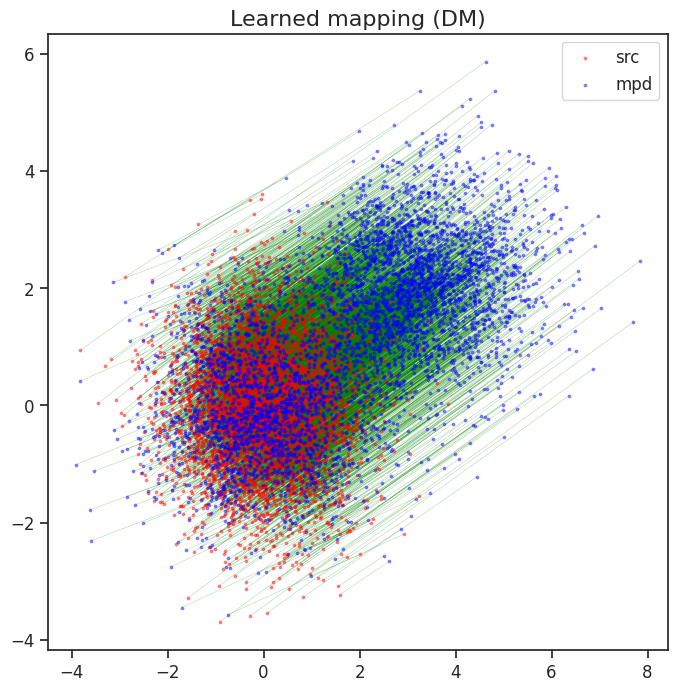

100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 10000/10000 [05:23<00:00, 30.93it/s, friction=0, loss=6.94, scale=3.35]


In [8]:
MAX_ITER   = 10000
BATCH_SIZE = 16

_np_state, _torch_state = np.random.get_state(), torch.get_rng_state()
ema = EMA(0, betas=[0.999, 0.99])
np.random.set_state(_np_state); torch.set_rng_state(_torch_state)

loss_history = []

print(f'Fitting the Gaussian Mixture with {_label}')
with tqdm(range(MAX_ITER)) as tbar:
    for iteration in tbar:
        X        = source_sampler.sample(BATCH_SIZE).to(DEVICE)
        Y_target = target_sampler.sample(BATCH_SIZE).to(DEVICE)
        Y_gen    = model(X)

        friction_coeff = (iteration / (MAX_ITER - 1)) if FRICTION_ON else 0.0

        loss, info = drift_loss_pytorch(
            Y_gen.unsqueeze(0),
            Y_target.unsqueeze(0),
            R_list=(0.02, 0.05, 0.15),
            friction_coeff=friction_coeff,
        )

        optim.zero_grad()
        loss.backward()
        optim.step()

        _np_state, _torch_state = np.random.get_state(), torch.get_rng_state()
        ema(model)
        np.random.set_state(_np_state); torch.set_rng_state(_torch_state)

        loss_history.append(loss.item())
        tbar.set_postfix(loss=loss.item(), scale=info["scale"].item(), friction=friction_coeff)

        if (iteration + 1) % 50 == 0:
            _np_state, _torch_state = np.random.get_state(), torch.get_rng_state()

            clear_output(wait=True)
            print(f"Iteration {iteration+1}  |  Loss: {loss.item():.4f}  |  Friction: {friction_coeff:.3f}")
            plt.figure(figsize=(6, 4))
            plt.plot(loss_history); plt.yscale('log')
            plt.title(f'{_label} Loss History')
            plt.savefig(loss_path); plt.close()

            with torch.no_grad():
                X_vis = source_sampler.sample(5000).to(DEVICE)
                Y_vis = model(X_vis)
            visualize_2d_map(
                X_vis.cpu().numpy(), Y_vis.cpu().numpy(), f'Learned mapping ({_label})',
                data_label='src', mapped_data_label='mpd',
                s=3, figsize=(8, 8), save_path=samples_path)

            torch.save(model.state_dict(), curr_model_path)
            for beta in [0.999, 0.99]:
                torch.save(ema.get_model(beta),
                           os.path.join(EXP_DIR, f'model_{beta}.pth'))

            np.random.set_state(_np_state); torch.set_rng_state(_torch_state)

In [9]:
# ═══════════════════════════════════════════════════════════════════════════════
# POST-TRAINING ANALYSIS
# ═══════════════════════════════════════════════════════════════════════════════

N_GEN    = 500
N_STEPS  = 100
time_pts = np.linspace(0.0, 1.0, N_STEPS)

model.eval()
with torch.no_grad():
    x0_np  = source_sampler.sample(N_GEN).cpu().numpy()
    x0_t   = torch.tensor(x0_np, dtype=torch.float32).to(DEVICE)
    x1_t   = model(x0_t)
    x1_np  = x1_t.cpu().numpy()

# straight interpolation for visualization (similar to OFM)
trajectory = np.stack(
    [(1 - t) * x0_np + t * x1_np for t in time_pts], axis=0
)
velocity_const = x1_np - x0_np


# ── Helper: angle-based point colors ──────────────────────────────────────────

def get_angle_colors(positions):
    angles     = np.arctan2(positions[:, 1], positions[:, 0])
    angles_deg = (np.degrees(angles) + 360) % 360
    colors     = np.zeros((len(positions), 3))
    for i, angle in enumerate(angles_deg):
        seg   = int(angle / 120)
        local = angle - seg * 120
        if   seg == 0: colors[i] = [1 - local/120, local/120, 0]
        elif seg == 1: colors[i] = [0, 1 - local/120, local/120]
        else:          colors[i] = [local/120, 0, 1 - local/120]
    return colors



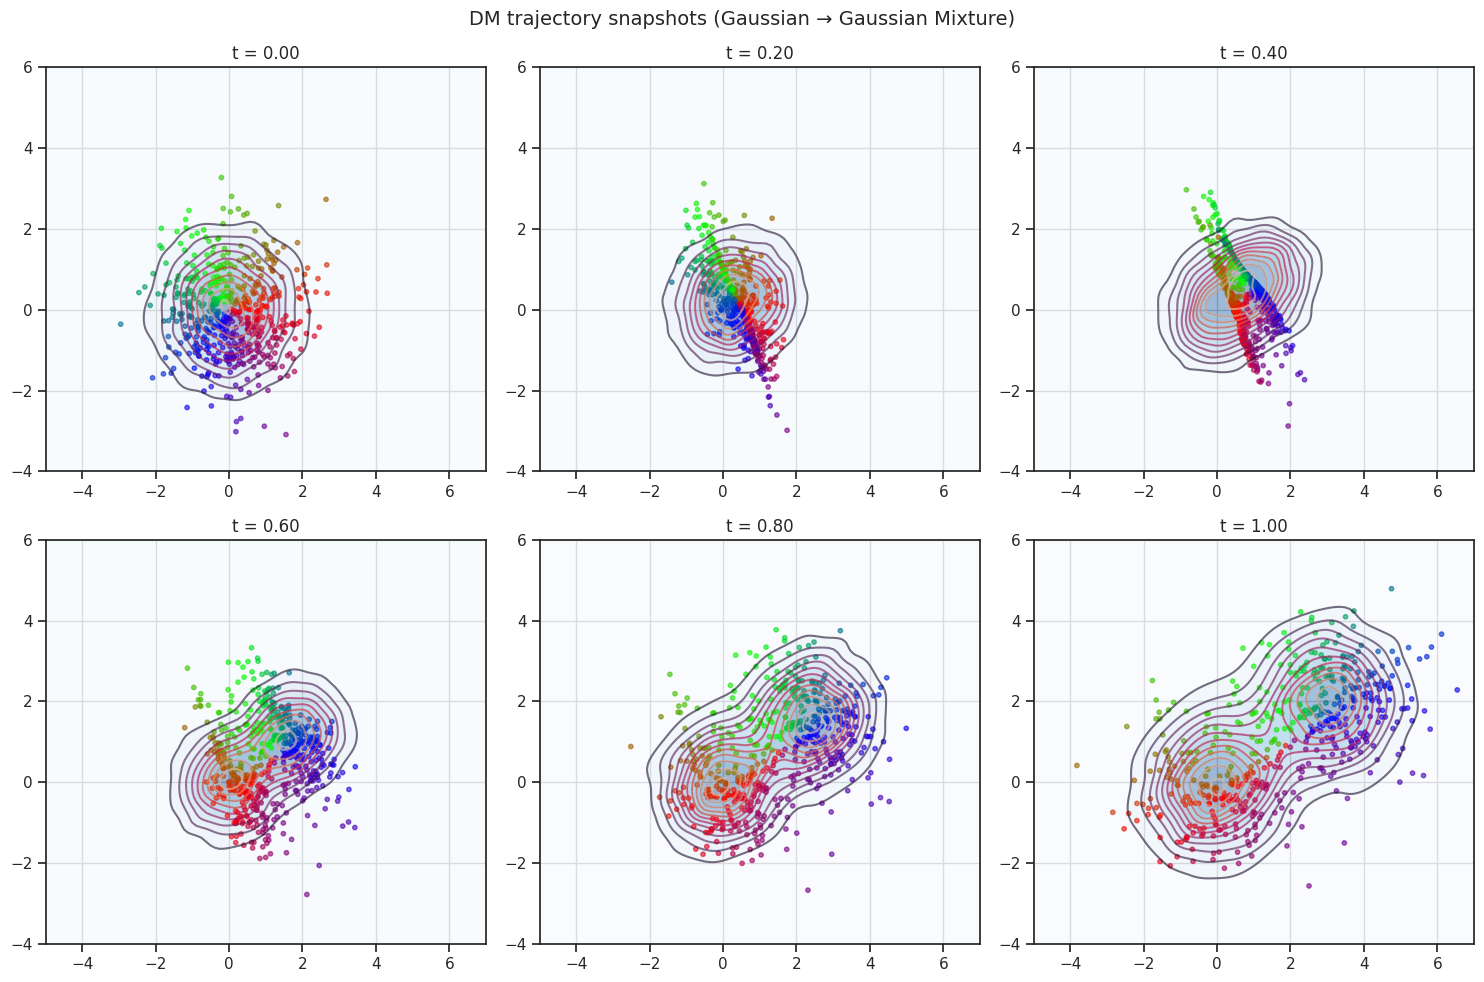

In [10]:
# ── 1. Trajectory snapshots ──────────────────────────────────────────────────

desired_times = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]
indices       = [np.argmin(np.abs(time_pts - tv)) for tv in desired_times]
point_colors  = get_angle_colors(x0_np)

xx, yy  = np.mgrid[-5:7:100j, -4:6:100j]
grid_pts = np.vstack([xx.ravel(), yy.ravel()])

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
fig.suptitle('DM trajectory snapshots (Gaussian → Gaussian Mixture)', fontsize=14)

for i, idx in enumerate(indices):
    ax  = axes[i // 3, i % 3]
    t   = time_pts[idx]
    x_t = trajectory[idx]

    x1_ref   = mixture.sample_np(5000)
    eps      = np.random.randn(5000, 2)
    x_fwd    = t * x1_ref + (1 - t) * eps
    kernel   = gaussian_kde(x_fwd.T)
    density  = kernel(grid_pts).reshape(xx.shape)

    ax.contourf(xx, yy, density, levels=12, cmap='Blues', alpha=0.4)
    ax.contour (xx, yy, density, levels=12, alpha=0.6)
    ax.scatter(x_t[:, 0], x_t[:, 1], c=point_colors, alpha=0.6, s=10)
    ax.set_title(f't = {t:.2f}')
    ax.set_xlim(-5, 7); ax.set_ylim(-4, 6)
    ax.grid(True)

plt.tight_layout()
plt.show()



[DM]  Fréchet Distance (2D): 0.079089


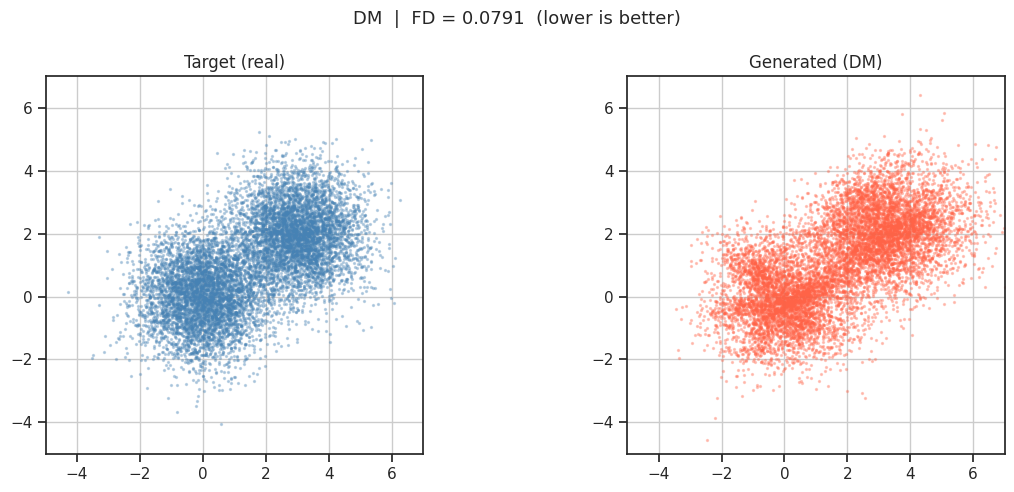

Saved generated and real samples → ./gaumix_dm/


In [11]:
# ── Fréchet Distance (2D FID) + Save samples ─────────────────────────────────
from scipy.linalg import sqrtm

def frechet_distance(real_samples, gen_samples):
    mu_r = real_samples.mean(axis=0)
    mu_g = gen_samples.mean(axis=0)
    sigma_r = np.cov(real_samples, rowvar=False)
    sigma_g = np.cov(gen_samples, rowvar=False)
    diff = mu_r - mu_g
    covmean = sqrtm(sigma_r @ sigma_g)
    if np.iscomplexobj(covmean):
        covmean = covmean.real
    return float(diff @ diff + np.trace(sigma_r + sigma_g - 2 * covmean))

N_FD = 10_000

# Reset RNG to training seed before evaluation so results match run_table2.py
seed_everything(SEED)

model.eval()
with torch.no_grad():
    x_src = source_sampler.sample(N_FD).to(DEVICE)
    x_gen = model(x_src).cpu().numpy()

x_real = target_sampler.sample_np(N_FD)

fd = frechet_distance(x_real, x_gen)
print(f"[{_label}]  Fréchet Distance (2D): {fd:.6f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle(f'{_label}  |  FD = {fd:.4f}  (lower is better)', fontsize=13)

for ax, pts, label, color in zip(
    axes,
    [x_real, x_gen],
    ['Target (real)', f'Generated ({_label})'],
    ['steelblue', 'tomato'],
):
    ax.scatter(pts[:, 0], pts[:, 1], s=2, alpha=0.3, color=color)
    ax.set_title(label)
    ax.set_xlim(-5, 7); ax.set_ylim(-5, 7)
    ax.set_aspect('equal'); ax.grid(True)

plt.tight_layout()
plt.savefig(os.path.join(EXP_DIR, 'fd_comparison.png'), dpi=120)
plt.show()

np.save(os.path.join(EXP_DIR, 'generated_samples.npy'), x_gen)
np.save(os.path.join(EXP_DIR, 'real_samples.npy'),      x_real)
print(f"Saved generated and real samples → {EXP_DIR}/")